# Task-Aware Conditioning and Attention-Pooling Architectures

LRNG: National (India) | CC: Human Values | SDG: 3 | Data: Time series | Thrust: Intelligent Edge Technologies | Screening aid only

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score, confusion_matrix
import data_loading.v2_loader as v2

np.random.seed(42)
tf.random.set_seed(42)

Loading PADS 100 Hz 6-channel IMU windows, metadata, one-hot task embeddings, and 3-split folds

In [2]:
pads_data, pads_meta = v2.load_v1_pads_data(results_dir=os.path.join("..", "results"))
task_one_hot = v2.get_task_one_hot(pads_meta)
splits = v2.load_fold_splits(results_dir=os.path.join("..", "results"))

y_pads = pads_meta["cohort_label"].map({"Normal": 0, "Parkinsons-like": 1, "ET-like": 2}).values
groups = pads_meta["subject_id"].values
unique_subs = pads_meta["subject_id"].unique()
sub_true = np.array([y_pads[groups == s][0] for s in unique_subs])
target_names = ["Normal", "Parkinsons-like", "ET-like"]

Xd = pads_data - pads_data.mean(axis=1, keepdims=True)

print("PADS windows shape:", pads_data.shape)
print("Task one-hot shape:", task_one_hot.shape)
print("Unique subjects:", len(unique_subs))

PADS windows shape: (25500, 300, 6)
Task one-hot shape: (25500, 5)
Unique subjects: 375


Defining Model 1 (Task-Aware Strided Conv1D + BiLSTM) and Model 2 (Subject Attention-Pooling Head)

In [3]:
def build_task_aware_window_model(input_shape=(300, 6), task_dim=5, num_classes=3):
    imu_in = layers.Input(shape=input_shape)
    task_in = layers.Input(shape=(task_dim,))
    
    x = layers.Conv1D(32, kernel_size=5, strides=2, padding="same", activation="relu")(imu_in)
    x = layers.Conv1D(32, kernel_size=3, strides=2, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=True))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(16))(x)
    x = layers.Dropout(0.3)(x)
    
    t = layers.Dense(16, activation="relu")(task_in)
    concat = layers.Concatenate()([x, t])
    emb = layers.Dense(32, activation="relu")(concat)
    out = layers.Dense(num_classes, activation="softmax")(emb)
    
    model = models.Model(inputs=[imu_in, task_in], outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def build_attention_pooling_head(num_windows=68, emb_dim=32, num_classes=3):
    inp = layers.Input(shape=(num_windows, emb_dim))
    score = layers.Dense(16, activation="tanh")(inp)
    score = layers.Dense(1)(score)
    weights = layers.Softmax(axis=1)(score)
    pooled = layers.Lambda(lambda x: tf.reduce_sum(x[0] * x[1], axis=1))([inp, weights])
    x = layers.Dense(32, activation="relu")(pooled)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs=inp, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

sample_m1 = build_task_aware_window_model()
print("Model 1 (Task-Aware Window Model) total parameters:", sample_m1.count_params())
sample_m2 = build_attention_pooling_head()
print("Model 2 (Attention-Pooling Head) total parameters:", sample_m2.count_params())

Model 1 (Task-Aware Window Model) total parameters: 32867


Model 2 (Attention-Pooling Head) total parameters: 1700


Training and evaluating both models across 3 split seeds (seeds 42, 43, 44; 15 folds total)

In [4]:
split_seeds = [42, 43, 44]

m1_seed_sub_probs = []
m1_seed_win_probs = []
m1_seed_sub_f1 = []
m1_seed_sub_bacc = []

m2_seed_sub_probs = []
m2_seed_sub_f1 = []
m2_seed_sub_bacc = []

sample_m1_history = None
sample_m2_history = None

sub_to_idx = {s: i for i, s in enumerate(unique_subs)}

for s in split_seeds:
    tf.random.set_seed(s)
    np.random.seed(s)
    
    m1_oof_probs = np.zeros((len(y_pads), 3), dtype=np.float32)
    m2_oof_sub_probs = np.zeros((len(unique_subs), 3), dtype=np.float32)
    
    for fold in range(5):
        tr_idx = splits[f"split_{s}_tr_{fold}"]
        te_idx = splits[f"split_{s}_te_{fold}"]
        
        ch_std = Xd[tr_idx].std(axis=(0, 1))
        ch_std[ch_std == 0] = 1.0
        Xn_tr = (Xd[tr_idx] / ch_std).astype(np.float32)
        Xn_te = (Xd[te_idx] / ch_std).astype(np.float32)
        
        Xn_tr_aug = v2.apply_amplitude_aware_augmentation(Xn_tr, jitter_sigma=0.03, max_shift=15, mirror_prob=0.5, seed=s + fold)
        task_tr = task_one_hot[tr_idx]
        task_te = task_one_hot[te_idx]
        
        cw = compute_class_weight("balanced", classes=np.unique(y_pads[tr_idx]), y=y_pads[tr_idx])
        cw_dict = dict(enumerate(cw))
        
        tf.keras.backend.clear_session()
        m1 = build_task_aware_window_model()
        cb_m1 = [
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
        ]
        h1 = m1.fit(
            [Xn_tr_aug, task_tr], y_pads[tr_idx],
            validation_split=0.15, epochs=12, batch_size=256,
            class_weight=cw_dict, callbacks=cb_m1, verbose=0
        )
        if sample_m1_history is None:
            sample_m1_history = h1.history
            
        m1_oof_probs[te_idx] = m1.predict([Xn_te, task_te], batch_size=1024, verbose=0)
        
        encoder = models.Model(inputs=m1.inputs, outputs=m1.layers[-2].output)
        embs_tr_all = encoder.predict([Xn_tr, task_tr], batch_size=1024, verbose=0)
        embs_te_all = encoder.predict([Xn_te, task_te], batch_size=1024, verbose=0)
        
        tr_subs = np.unique(groups[tr_idx])
        te_subs = np.unique(groups[te_idx])
        
        H_tr = np.array([embs_tr_all[groups[tr_idx] == sub] for sub in tr_subs])
        y_sub_tr = np.array([y_pads[groups == sub][0] for sub in tr_subs])
        H_te = np.array([embs_te_all[groups[te_idx] == sub] for sub in te_subs])
        
        sub_cw = compute_class_weight("balanced", classes=np.unique(y_sub_tr), y=y_sub_tr)
        sub_cw_dict = dict(enumerate(sub_cw))
        
        m2 = build_attention_pooling_head()
        cb_m2 = [
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
        ]
        h2 = m2.fit(
            H_tr, y_sub_tr, validation_split=0.15,
            epochs=25, batch_size=32, class_weight=sub_cw_dict,
            callbacks=cb_m2, verbose=0
        )
        if sample_m2_history is None:
            sample_m2_history = h2.history
            
        te_sub_preds = m2.predict(H_te, verbose=0)
        for sub, p in zip(te_subs, te_sub_preds):
            m2_oof_sub_probs[sub_to_idx[sub]] = p
            
    m1_sub_p = np.array([np.mean(m1_oof_probs[groups == sub], axis=0) for sub in unique_subs])
    m1_sub_pred = np.argmax(m1_sub_p, axis=1)
    m1_f1 = float(f1_score(sub_true, m1_sub_pred, average="macro"))
    m1_bacc = float(balanced_accuracy_score(sub_true, m1_sub_pred))
    m1_seed_sub_f1.append(m1_f1)
    m1_seed_sub_bacc.append(m1_bacc)
    m1_seed_sub_probs.append(m1_sub_p)
    m1_seed_win_probs.append(m1_oof_probs)
    
    m2_sub_pred = np.argmax(m2_oof_sub_probs, axis=1)
    m2_f1 = float(f1_score(sub_true, m2_sub_pred, average="macro"))
    m2_bacc = float(balanced_accuracy_score(sub_true, m2_sub_pred))
    m2_seed_sub_f1.append(m2_f1)
    m2_seed_sub_bacc.append(m2_bacc)
    m2_seed_sub_probs.append(m2_oof_sub_probs)
    
    print(f"Seed {s} -> Task-Aware Model: Subject Macro-F1 = {m1_f1:.4f}, Balanced Acc = {m1_bacc:.4f}")
    print(f"Seed {s} -> Attention-Pooling Model: Subject Macro-F1 = {m2_f1:.4f}, Balanced Acc = {m2_bacc:.4f}")

Seed 42 -> Task-Aware Model: Subject Macro-F1 = 0.4681, Balanced Acc = 0.6028
Seed 42 -> Attention-Pooling Model: Subject Macro-F1 = 0.4899, Balanced Acc = 0.6207


Seed 43 -> Task-Aware Model: Subject Macro-F1 = 0.4823, Balanced Acc = 0.5699
Seed 43 -> Attention-Pooling Model: Subject Macro-F1 = 0.5045, Balanced Acc = 0.5321


Seed 44 -> Task-Aware Model: Subject Macro-F1 = 0.5275, Balanced Acc = 0.6361
Seed 44 -> Attention-Pooling Model: Subject Macro-F1 = 0.5210, Balanced Acc = 0.5888


Evaluating seed-averaged pooled metrics, bootstrap confidence intervals, and One-vs-Rest AUROCs

In [5]:
def evaluate_and_format(name, seed_sub_probs, seed_win_probs=None):
    avg_sub_p = np.mean(seed_sub_probs, axis=0)
    sub_preds = np.argmax(avg_sub_p, axis=1)
    
    mean_sub_f1 = float(f1_score(sub_true, sub_preds, average="macro"))
    mean_sub_bacc = float(balanced_accuracy_score(sub_true, sub_preds))
    
    f1_ci = v2.compute_bootstrap_ci(sub_true, avg_sub_p, lambda yt, p: f1_score(yt, np.argmax(p, axis=1), average="macro"))
    bacc_ci = v2.compute_bootstrap_ci(sub_true, avg_sub_p, lambda yt, p: balanced_accuracy_score(yt, np.argmax(p, axis=1)))
    
    auc_norm = float(roc_auc_score(sub_true == 0, avg_sub_p[:, 0]))
    auc_pd = float(roc_auc_score(sub_true == 1, avg_sub_p[:, 1]))
    auc_et = float(roc_auc_score(sub_true == 2, avg_sub_p[:, 2]))
    auc_macro = float((auc_norm + auc_pd + auc_et) / 3.0)
    
    if seed_win_probs is not None:
        avg_win_p = np.mean(seed_win_probs, axis=0)
        win_preds = np.argmax(avg_win_p, axis=1)
        win_f1 = float(f1_score(y_pads, win_preds, average="macro"))
        win_bacc = float(balanced_accuracy_score(y_pads, win_preds))
    else:
        win_f1 = np.nan
        win_bacc = np.nan
        
    print(f"\n=== {name} Pooled Results across 3 Split Seeds ===")
    print(f"Pooled Subject Macro-F1: {mean_sub_f1:.4f} [95% Bootstrap CI: {f1_ci[0]:.4f} - {f1_ci[1]:.4f}]")
    print(f"Pooled Subject Balanced Acc: {mean_sub_bacc:.4f} [95% Bootstrap CI: {bacc_ci[0]:.4f} - {bacc_ci[1]:.4f}]")
    print(f"Subject One-vs-Rest AUROC: Normal={auc_norm:.4f}, PD={auc_pd:.4f}, ET={auc_et:.4f}, Macro={auc_macro:.4f}")
    if not np.isnan(win_f1):
        print(f"Window-Level Macro-F1: {win_f1:.4f} | Balanced Acc: {win_bacc:.4f}")
        
    cm = confusion_matrix(sub_true, sub_preds)
    print("Subject Confusion Matrix:")
    print(pd.DataFrame(cm, index=[f"True_{c}" for c in target_names], columns=[f"Pred_{c}" for c in target_names]))
    for i, c in enumerate(target_names):
        rec = float(cm[i, i] / np.sum(cm[i]))
        print(f"Recall for {c}: {rec:.4f}")
        
    return {
        "Model": name,
        "Sampling_Rate": "100 Hz",
        "Channels": 6,
        "Subject_Macro_F1": mean_sub_f1,
        "Subject_F1_CI_Low": f1_ci[0],
        "Subject_F1_CI_High": f1_ci[1],
        "Subject_Balanced_Acc": mean_sub_bacc,
        "Subject_BAcc_CI_Low": bacc_ci[0],
        "Subject_BAcc_CI_High": bacc_ci[1],
        "AUROC_Normal": auc_norm,
        "AUROC_PD": auc_pd,
        "AUROC_ET": auc_et,
        "AUROC_Macro": auc_macro,
        "Window_Macro_F1": win_f1,
        "Window_Balanced_Acc": win_bacc
    }

res_m1 = evaluate_and_format("Task-Aware Conv1D + BiLSTM", m1_seed_sub_probs, m1_seed_win_probs)
res_m2 = evaluate_and_format("Attention-Pooling Subject Model", m2_seed_sub_probs)

v2_records = [res_m1, res_m2]
os.makedirs(os.path.join("..", "results", "metrics"), exist_ok=True)
df_metrics = pd.DataFrame(v2_records)
df_metrics.to_csv(os.path.join("..", "results", "metrics", "v2_track1_task_aware_attention.csv"), index=False)
print("\nSaved results to results/metrics/v2_track1_task_aware_attention.csv successfully")


=== Task-Aware Conv1D + BiLSTM Pooled Results across 3 Split Seeds ===
Pooled Subject Macro-F1: 0.5334 [95% Bootstrap CI: 0.4629 - 0.5934]
Pooled Subject Balanced Acc: 0.6292 [95% Bootstrap CI: 0.5547 - 0.7005]
Subject One-vs-Rest AUROC: Normal=0.8001, PD=0.6767, ET=0.8437, Macro=0.7735
Window-Level Macro-F1: 0.4120 | Balanced Acc: 0.5304
Subject Confusion Matrix:
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    63                    16             0
True_Parkinsons-like          101                   139            28
True_ET-like                    3                     9            16
Recall for Normal: 0.7975
Recall for Parkinsons-like: 0.5187
Recall for ET-like: 0.5714



=== Attention-Pooling Subject Model Pooled Results across 3 Split Seeds ===
Pooled Subject Macro-F1: 0.5602 [95% Bootstrap CI: 0.4975 - 0.6176]
Pooled Subject Balanced Acc: 0.6813 [95% Bootstrap CI: 0.6090 - 0.7474]
Subject One-vs-Rest AUROC: Normal=0.8185, PD=0.6935, ET=0.8316, Macro=0.7812
Subject Confusion Matrix:
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    62                    17             0
True_Parkinsons-like           84                   146            38
True_ET-like                    1                     7            20
Recall for Normal: 0.7848
Recall for Parkinsons-like: 0.5448
Recall for ET-like: 0.7143

Saved results to results/metrics/v2_track1_task_aware_attention.csv successfully


Saving representative loss and accuracy curves for Task-Aware and Attention-Pooling architectures

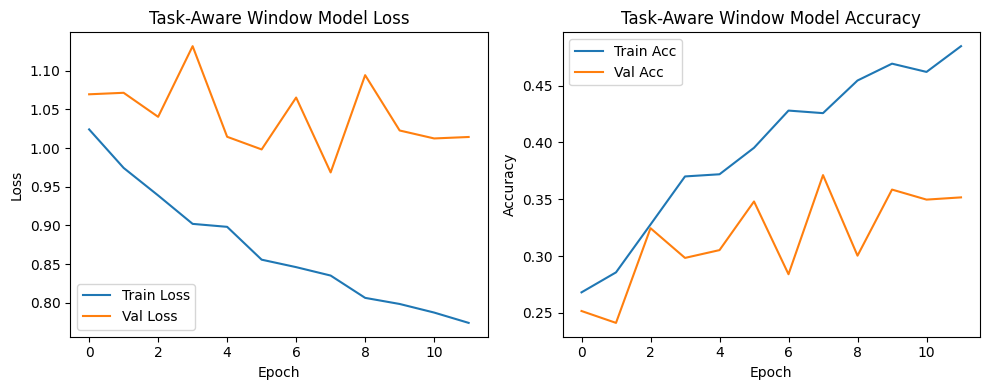

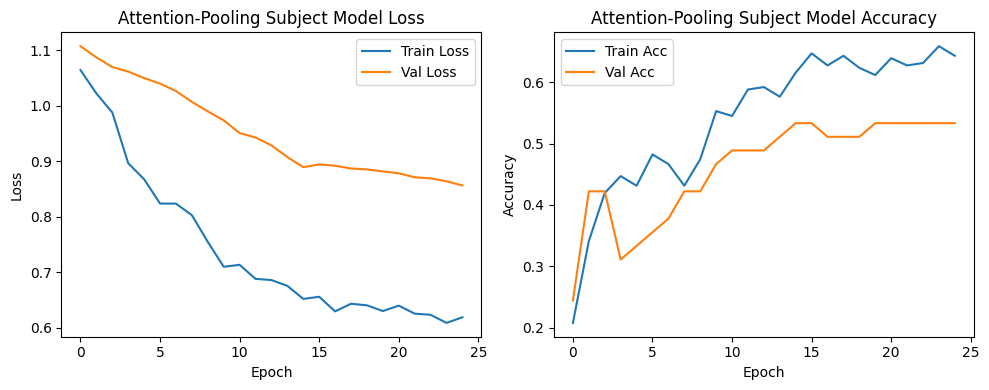

In [6]:
os.makedirs(os.path.join("..", "results", "plots"), exist_ok=True)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(sample_m1_history["loss"], label="Train Loss")
plt.plot(sample_m1_history["val_loss"], label="Val Loss")
plt.title("Task-Aware Window Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(sample_m1_history["accuracy"], label="Train Acc")
plt.plot(sample_m1_history["val_accuracy"], label="Val Acc")
plt.title("Task-Aware Window Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join("..", "results", "plots", "v2_task_aware_curves.png"), dpi=150)
plt.show()

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(sample_m2_history["loss"], label="Train Loss")
plt.plot(sample_m2_history["val_loss"], label="Val Loss")
plt.title("Attention-Pooling Subject Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(sample_m2_history["accuracy"], label="Train Acc")
plt.plot(sample_m2_history["val_accuracy"], label="Val Acc")
plt.title("Attention-Pooling Subject Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join("..", "results", "plots", "v2_attention_curves.png"), dpi=150)
plt.show()